# Commuting zones: local characteristics and life expectancy

Life expectancy varies by several years across US commuting zones among men
in the bottom quarter of the national income distribution. This study models
that geographic variation using local health, economic and demographic
characteristics.

It examines the conditional associations of local characteristics with that
gap — smoking rates, insurance coverage, hospital quality, segregation,
schooling, and more than thirty other measures recorded for each area. The
difficulty is that those characteristics come in bundles. Areas where people
smoke more are also areas that are poorer, less educated and in particular
parts of the country, so a characteristic can appear to matter simply by
travelling with one that does.

This advanced case teaches how to combine a large learner menu, spatial structure and
stability selection on an ecological data set. Recorded multi-outcome runs are separated
from the live fit that explains the workflow.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | which local characteristics go with longer lives among poor American men |
| **Observed response** | life expectancy at 40 for men in the bottom income quartile |
| **Estimand** | the association between each local characteristic and life expectancy, conditional on the others |
| **Units** | years of life expectancy; the covariates on their own published scales |
| **Sampling unit** | one commuting zone |
| **Dependence** | commuting zones are spatially arranged and neighbouring zones resemble each other; the folds do not account for that, which the study notes |
| **Split / resampling unit** | the commuting zone |
| **Tuning** | `mstop` by cross-validated risk |
| **Uncertainty** | stability selection frequencies and bootstrap refits |
| **Claim type** | descriptive association. Nothing here identifies what would happen if a characteristic changed |
:::


In [1]:
import json
import pathlib

import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

raw = mb.datasets.hip_cz()
outcome = "le_raceadj_q1_M"

le_all = raw[outcome].drop_nulls().to_numpy()
best = raw.sort(outcome, descending=True).row(0, named=True)
worst = raw.sort(outcome).row(0, named=True)
le_gap = f"{le_all.max() - le_all.min():.1f}"
le_spread = f"{np.percentile(le_all, 90) - np.percentile(le_all, 10):.1f}"
best_zone = f"{best['czname']}, {best['stateabbrv']} ({best[outcome]:.1f} years)"
worst_zone = f"{worst['czname']}, {worst['stateabbrv']} ({worst[outcome]:.1f} years)"

display(raw.select(["cz", "czname", "pop2000", outcome,
                    "cur_smoke_q1", "reimb_penroll_adj10"]).head(5))


cz,czname,pop2000,le_raceadj_q1_M,cur_smoke_q1,reimb_penroll_adj10
i64,str,i64,f64,f64,f64
100,"""Johnson City""",576081,75.968956,0.351208,10121.918
200,"""Morristown""",227816,75.419853,0.419753,10228.286
301,"""Middlesborough""",66708,76.098907,0.364103,12756.419
302,"""Knoxville""",727600,75.08934,0.324125,9913.499
401,"""Winston-Salem""",493180,75.910576,0.323423,9635.791


The measure is expected age at death for a 40-year-old man in the bottom
quarter of the income distribution, adjusted so that differences in the racial
composition of areas do not drive it. It runs from {eval}`worst_zone` to
{eval}`best_zone`: a gap of {eval}`le_gap` years, and still {eval}`le_spread`
years between a typical low area and a typical high one.

{cite:t}`chetty2016inequality`, who built this data, asked which local
characteristics go with that gap, and answered by correlating life expectancy
with each characteristic on its own. The paper reports that for the poorest
quarter, life expectancy goes with health behaviours — smoking, obesity,
exercise — and not with healthcare access, environmental factors, or
labour-market conditions.

Separate correlations do not adjust for relationships among the predictors.
Smoking, obesity and schooling can each correlate with life expectancy partly
because they correlate with one another. The joint model below fits these
characteristics together and includes spatial effects, so their fitted
contributions depend on which other terms have already reduced the residual
error.


## The data

The areas are *commuting zones*: clusters of counties that people commute
within, which is to say local labour markets rather than cities or counties.
There are 741 covering the country, and the study reports the 595 with more
than 25,000 residents.

`mb.datasets.hip_cz()` is the Health Inequality Project's commuting-zone file.
Its outcome columns are life expectancy at 40 by gender and by income quarter:
`le_raceadj_q1_M` is men in the bottom quarter, `q4` is the top quarter. Its
other columns are the local characteristics, in nine families — health
behaviours, healthcare access and quality, income inequality, segregation,
social cohesion, labour market, education, migration and composition, local
government — plus each zone's population, the census division it sits in, and
the longitude and latitude of its centre.

Every row is a place. A characteristic's value is that zone's rate or average
and the outcome is that zone's life expectancy; no row describes a person.

## Published and recomputed correlations

The paper's supplement reports the correlation of each characteristic with
life expectancy, 152 of them (two genders × two income quarters × the
characteristics). The study scripts recompute all 152 from this file and
reproduce each to the two decimals the paper prints. Six are shown here:
`published` is what the paper prints, `computed` is what the file gives.


In [2]:
spot = pl.DataFrame(json.loads(
    pathlib.Path("cz_inequality.json").read_text())["validation"]["spot_rows"])
spot = spot.with_columns(
    (pl.col("computed") - pl.col("published")).round(4).alias("difference"))
display(spot)
spot_max = f'{spot["difference"].abs().max():.4f}'
print("max |difference|:", spot_max)


variable,outcome,published,computed,difference
str,str,f64,f64,f64
"""cur_smoke_q1""","""le_raceadj_q1_M""",-0.7,-0.6978,0.0022
"""cur_smoke_q4""","""le_raceadj_q4_M""",-0.34,-0.3414,-0.0014
"""exercise_any_q1""","""le_raceadj_q1_M""",0.39,0.39,0.0
"""puninsured2010""","""le_raceadj_q4_M""",-0.4,-0.4016,-0.0016
"""puninsured2010""","""le_raceadj_q1_M""",0.09,0.0898,-0.0002
"""cs_born_foreign""","""le_raceadj_q1_M""",0.76,0.7601,0.0001


max |difference|: 0.0022


The largest of the six differences is {eval}`spot_max`.


## Component-wise boosting model

The model is built by *component-wise boosting*. It starts from a flat
prediction — every zone gets the national average — and improves it in small
steps. At each step it looks at every characteristic on its own, asks which one
best reduces the error that remains, and adds a small amount of that one. The
step is small, so a characteristic that keeps helping gets picked repeatedly
and one that helps only once or twice barely enters.

Each update is chosen from fits to the current residuals. Correlated
characteristics can substitute for one another, so selection and the allocation
of risk reduction depend on the path. Because each update is small, both
members of a correlated pair can still be selected before their shared
association has been fully fitted.

Three kinds of candidate compete at every step:

- **Each characteristic, twice.** `bols(x, intercept=False)` fits a straight
  line in the characteristic. `bbs(x, center=True, df=1)` fits only what a
  straight line misses: `center=True` takes the straight-line part out of the
  spline's basis, so the pair splits the effect between them instead of
  overlapping — one candidate for the slope, one for the departure from it.
  Each is allowed one degree of freedom, so a curved effect is not picked over
  a straight one merely for having more freedom to chase noise
  {cite:p}`hofner2011framework`. Centering is also what makes `df=1` possible:
  an uncentered P-spline keeps a straight line no matter how hard it is
  penalised, so it cannot be reduced below two degrees of freedom, and mboostrs
  rejects the attempt.
- **The map.** `bspatial(lon, lat, df=6)` fits a smooth surface over the zones'
  coordinates: a sheet stretched over the country that is free to bend but
  penalized for bending sharply. It competes on the same terms as any
  characteristic, so what it ends up holding is whatever is common to nearby
  zones and is not explained by the measured characteristics.
- **The census division.** `brandom(census_division)` fits one number per
  division, pulled toward zero unless the data insist otherwise.

Characteristics are centred before fitting, and put on a common scale at the
same time. The centring is what matters: `bols(x, intercept=False)` fits a line
through the origin, so given a raw column a candidate spends its one coefficient
partly on reaching the level of the response rather than on its relation to it.
The rescaling changes nothing about which candidate is picked — every candidate
here is fitted at a fixed number of degrees of freedom, and that calibration is
unaffected by the units — but it makes the fitted coefficients comparable
across characteristics.


In [3]:
GROUPS = {
    "cur_smoke_q1", "bmi_obese_q1", "exercise_any_q1", "puninsured2010",
    "reimb_penroll_adj10", "mort_30day_hosp_z", "med_prev_qual_z",
    "primcarevis_10", "diab_eyeexam_10", "mammogram_10",
    "amb_disch_per1000_10", "gini99", "poor_share", "inc_share_1perc",
    "frac_middleclass", "cs00_seg_inc", "cs00_seg_inc_pov25",
    "cs00_seg_inc_aff75", "cs_race_theil_2000", "scap_ski90pcm", "rel_tot",
    "crime_total", "unemp_rate", "cs_labforce", "cs_elf_ind_man",
    "pop_d_2000_1980", "cs_educ_ba", "dropout_r", "ccd_pup_tch_ratio",
    "ccd_exp_tot", "mig_inflow", "mig_outflow", "cs_frac_black",
    "cs_frac_hisp", "cs_born_foreign", "pop_density", "subcty_exp_pc",
    "taxrate", "tax_st_diff_top20",
}
# Compute the table or diagnostic interpreted in the following paragraph.
complete = raw.drop_nulls(subset=[outcome, "lon", "lat", "census_div",
                                  *GROUPS])

characteristics = [c for c in complete.columns if c in GROUPS]

frame = complete.with_columns([
    ((pl.col(c) - pl.col(c).mean()) / pl.col(c).std()).alias(c)
    for c in characteristics
])

data = {c: frame[c].to_numpy() for c in frame.columns}

data["census_division"] = frame["census_div"].cast(str).to_numpy()

terms = []


In [4]:
for c in characteristics:
    terms.append(f"bols({c}, intercept=False)")
    terms.append(f"bbs({c}, center=True, df=1)")

terms.append("bspatial(lon, lat, df=6)")

terms.append("brandom(census_division)")

formula = f"{outcome} ~ " + " + ".join(terms)

# Quantities the prose quotes. Every number in a sentence below comes from one
# of these names through an {eval} expression, so a rerun that moves a value
# moves the sentence with it.

n_characteristics = len(characteristics)

n_candidates = len(terms)

n_zones = complete.height

n_zones_file = raw.height

n_dropped = n_zones_file - n_zones

n_missing_dropout = raw["dropout_r"].null_count()

life_expectancy = complete[outcome].to_numpy()

le_sd = f"{life_expectancy.std():.2f}"

pairs = np.corrcoef(np.column_stack(
    [complete[c].to_numpy() for c in characteristics]), rowvar=False)


In [5]:
upper = np.abs(pairs[np.triu_indices(n_characteristics, 1)])

n_pairs = len(upper)

pairs_over_half = f"{(upper > 0.5).mean():.0%}"

pairs_max = f"{upper.max():.2f}"

flat = np.abs(pairs - np.eye(n_characteristics))

i, j = np.unravel_index(flat.argmax(), flat.shape)

pairs_max_names = f"{characteristics[i]} and {characteristics[j]}"

print(f"{n_zones} zones, {n_candidates} candidates")

print(f"characteristic pairs correlated above 0.5: {pairs_over_half} "
      f"of {n_pairs}; largest {pairs_max}")


437 zones, 80 candidates
characteristic pairs correlated above 0.5: 8% of 741; largest 0.99


The analysis uses the {eval}`n_zones` zones with no missing value anywhere.
The {eval}`n_dropped` dropped zones are missing at least one characteristic,
{eval}`n_missing_dropout` of them the high-school dropout rate alone.

Each of the {eval}`n_characteristics` characteristics contributes two
candidates; with the map and the census division that makes
{eval}`n_candidates` candidates competing on {eval}`n_zones` zones. They are
bundled as expected: {eval}`pairs_over_half` of the {eval}`n_pairs` pairs of
characteristics correlate above 0.5 in absolute value, and the closest pair,
{eval}`pairs_max_names`, correlates {eval}`pairs_max` — two measures of income
segregation that are all but the same column twice.


Boosting has to be stopped. Left running it keeps adding detail until it is
fitting the noise in these particular zones, so the number of steps is itself a
choice. `cvrisk` makes it by holding zones out: the model is refitted on 25
random resamples of the zones, and after each step the error is measured on the
zones that resample left out. The step count with the lowest held-out error is
where the model stops.


In [6]:
fit = mb.gamboost(formula, data=data, family=mb.Gaussian(),
                  control=mb.boost_control(3000, 0.1))
cv = fit.cvrisk(type="bootstrap", B=25, seed=42)
mstop = int(cv.optimal_mstop)
print("optimal mstop:", mstop)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 1 learner(s): brandom(brandom(census_division)): 5.8 of 8 df after 52 selections (one step: 2.53). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)


optimal mstop: 2469


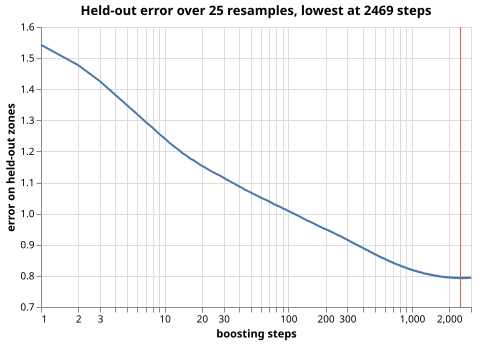

In [7]:
# Step 0 is the flat, average-only fit; it is dropped because the axis is
# logarithmic and log(0) is undefined -- plotted, it collapses the whole curve
# onto the y axis.
curve = pl.DataFrame({
    "mstop": np.asarray(cv.grid),
    "risk": np.asarray(cv.aggregate),
}).filter(pl.col("mstop") >= 1)
base = alt.Chart(curve).mark_line().encode(
    x=alt.X("mstop:Q", title="boosting steps",
            scale=alt.Scale(type="log", nice=False)),
    y=alt.Y("risk:Q", title="error on held-out zones",
            scale=alt.Scale(zero=False)),
)
rule = alt.Chart(pl.DataFrame({"m": [mstop]})).mark_rule(
    color="#e15759").encode(x="m:Q")
(base + rule).properties(
    title=f"Held-out error over 25 resamples, lowest at {mstop} steps",
    width=430, height=280)


## Stability selection

One fit on {eval}`n_zones` zones gives one answer. It does not say whether the
same characteristics would be picked from a different set of zones, and with
{eval}`n_candidates` candidates competing, some will be picked by luck.

*Stability selection* measures that directly. Half the zones are drawn at
random and the model is fitted on them, then fitted again on the half that was
left out, so each draw produces a pair of fits on complementary halves. A
hundred draws make 200 fits. Each fit is stopped as soon as ten distinct
candidates have been picked, and those ten are recorded. A characteristic's
**survival rate** is the share of the 200 fits that picked it: 1.00 means every
fit, 0.50 means half of them, which is another way of saying it depended on
which zones were in the sample.

Stopping every fit at the same ten picks is what makes the rates comparable,
and it is also what the error bound needs. Three quantities determine each
other — the number of candidates, the picks allowed per fit, and the survival
rate demanded — and fixing two of them bounds the expected number of
characteristics called survivors by chance
{cite:p}`meinshausen2010stability,shah2013variable`. Here the demand is at most
one false survivor, the `PFER=1` below, with {eval}`n_candidates` candidates and
ten picks per fit; the required rate follows, and the fit computes it. The
derivation, and the assumption about the selection probabilities that it rests
on, are in [](../methodology/stability_selection.ipynb).


In [8]:
model = mb.gamboost(formula, data=data, family=mb.Gaussian(),
                    control=mb.boost_control(mstop, 0.1))
stab = mb.stabsel(model, q=10, PFER=1.0, B=100, assumption="unimodal")
survival = pl.DataFrame({
    "candidate": model.base_learner_names(),
    "survival rate": np.asarray(stab.max_),
}).sort("survival rate", descending=True)
cutoff = f"{stab.cutoff:.3f}"
print(f"a candidate survives at {cutoff} or above")
display(survival.head(8))


a candidate survives at 0.805 or above


candidate,survival rate
str,f64
"""lon,lat""",1.0
"""cur_smoke_q1 (bols)""",0.99
"""reimb_penroll_adj10 (bols)""",0.875
"""pop_d_2000_1980 (bols)""",0.775
"""cs00_seg_inc (bbs)""",0.7
"""mort_30day_hosp_z (bols)""",0.58
"""pop_density (bols)""",0.425
"""reimb_penroll_adj10 (bbs)""",0.42


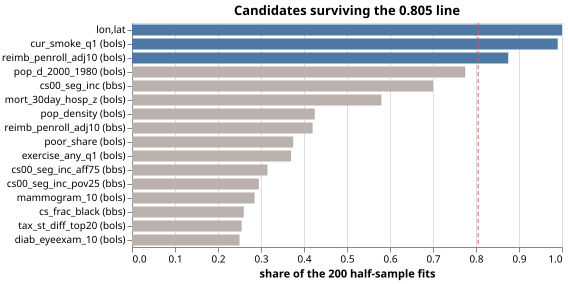

In [9]:
shown = survival.filter(pl.col("survival rate") >= 0.2)
bars = alt.Chart(shown).mark_bar(size=11).encode(
    y=alt.Y("candidate:N", title=None, sort="-x"),
    x=alt.X("survival rate:Q", title="share of the 200 half-sample fits",
            scale=alt.Scale(domain=[0, 1])),
    color=alt.condition(alt.datum["survival rate"] >= stab.cutoff,
                        alt.value("#4e79a7"), alt.value("#bab0ac")),
)
cutoff_rule = alt.Chart(
    pl.DataFrame({"c": [stab.cutoff]})
).mark_rule(color="#e15759", strokeDash=[4, 3]).encode(x="c:Q")
(bars + cutoff_rule).properties(
    title=f"Candidates surviving the {cutoff} line",
    width=430, height=alt.Step(14))


In [10]:
survivors = survival.filter(pl.col("survival rate") >= stab.cutoff)
n_survivors = survivors.height
n_below_third = int((survival["survival rate"] < 0.3).sum())
n_never = int((survival["survival rate"] == 0).sum())
survivor_list = ", ".join(f"{r['candidate']} at {r['survival rate']:.2f}"
                          for r in survivors.iter_rows(named=True))
print(survivor_list)


lon,lat at 1.00, cur_smoke_q1 (bols) at 0.99, reimb_penroll_adj10 (bols) at 0.88


The {eval}`cutoff` line is cleared by {eval}`n_survivors` candidates:
{eval}`survivor_list`. Of the other {eval}`n_candidates - n_survivors`,
{eval}`n_below_third` were picked in under 30% of the fits and
{eval}`n_never` were never picked at all.

The map is the strongest survivor, ahead of every measured characteristic.
Smoking is the only characteristic that is close to it.


## Correlation and selection frequency

The plot compares each characteristic's unadjusted correlation with life
expectancy on the horizontal axis and its stability-selection frequency on the
vertical axis. Some characteristics with large absolute correlations have low
selection frequencies when the other covariates and spatial terms are available.


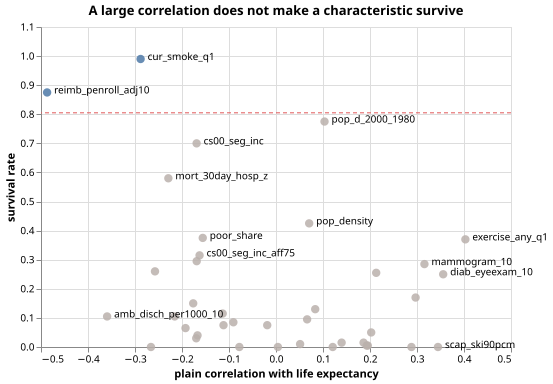

In [11]:
best_rate = {}
for name, rate in zip(model.base_learner_names(disambiguate=False), np.asarray(stab.max_)):
    best_rate[name] = max(best_rate.get(name, 0.0), float(rate))
r_with_le = {c: float(np.corrcoef(complete[c].to_numpy(),
                                  life_expectancy)[0, 1])
             for c in characteristics}
# Plot the quantities interpreted in the following paragraph.
scatter = pl.DataFrame([
    {"characteristic": c, "correlation": r_with_le[c],
     "survival rate": best_rate[c]}
    for c in characteristics
])
points = alt.Chart(scatter).mark_circle(size=70, opacity=0.85).encode(
    x=alt.X("correlation:Q",
            title="plain correlation with life expectancy"),
    y=alt.Y("survival rate:Q", title="survival rate",
            scale=alt.Scale(domain=[0, 1.05])),
    color=alt.condition(alt.datum["survival rate"] >= stab.cutoff,
                        alt.value("#4e79a7"), alt.value("#bab0ac")),
    tooltip=["characteristic:N", alt.Tooltip("correlation:Q", format=".2f"),
             alt.Tooltip("survival rate:Q", format=".2f")],
)
labelled = scatter.filter(
    (pl.col("survival rate") >= 0.3) | (pl.col("correlation").abs() >= 0.3))
labels = alt.Chart(labelled).mark_text(
    align="left", dx=7, dy=-2, fontSize=10).encode(
    x="correlation:Q", y="survival rate:Q", text="characteristic:N")
cutoff_rule = alt.Chart(
    pl.DataFrame({"c": [stab.cutoff]})
).mark_rule(color="#e15759", strokeDash=[4, 3]).encode(y="c:Q")
(points + labels + cutoff_rule).properties(
    title="A large correlation does not make a characteristic survive",
    width=470, height=320)


In [12]:
surface = np.asarray(model.partial_effects(which="lon,lat")["lon,lat"][1])
r_with_surface = {c: float(np.corrcoef(complete[c].to_numpy(), surface)[0, 1])
                  for c in characteristics}

# Characteristics a plain correlation would put near the top and the competition
# does not keep, against how much they overlap with the fitted map.
missed = sorted((c for c in characteristics
                 if abs(r_with_le[c]) >= 0.3 and best_rate[c] < stab.cutoff),
                key=lambda c: -abs(r_with_le[c]))
compare = missed + ["cur_smoke_q1", "reimb_penroll_adj10"]
display(pl.DataFrame([
    {"characteristic": c,
     "correlation with life expectancy": round(r_with_le[c], 2),
     "correlation with the map": round(r_with_surface[c], 2),
     "survival rate": round(best_rate[c], 2)}
    for c in compare
]))

n_missed = len(missed)
top_missed = missed[0]
top_missed_r = f"{r_with_le[top_missed]:.2f}"
top_missed_rate = f"{best_rate[top_missed]:.0%}"
missed_min_map = f"{min(abs(r_with_surface[c]) for c in missed):.2f}"
missed_max_rate = f"{max(best_rate[c] for c in missed):.0%}"
smoke_r = f"{r_with_le['cur_smoke_q1']:.2f}"
smoke_map = f"{r_with_surface['cur_smoke_q1']:.2f}"
smoke_rate = f"{best_rate['cur_smoke_q1']:.0%}"


characteristic,correlation with life expectancy,correlation with the map,survival rate
str,f64,f64,f64
"""exercise_any_q1""",0.4,0.55,0.37
"""amb_disch_per1000_10""",-0.36,-0.5,0.1
"""diab_eyeexam_10""",0.36,0.45,0.25
"""scap_ski90pcm""",0.34,0.63,0.0
"""mammogram_10""",0.32,0.42,0.28
"""cur_smoke_q1""",-0.29,-0.13,0.99
"""reimb_penroll_adj10""",-0.49,-0.68,0.88


In [13]:
DIVISIONS = {1: "New England", 2: "Middle Atlantic", 3: "East North Central",
             4: "West North Central", 5: "South Atlantic", 6: "South Central",
             8: "Mountain", 9: "Pacific"}


def where_the_highest_are(column, n=30):
    # Census divisions of the n zones scoring highest on `column`.
    top = complete.sort(column, descending=True).head(n)
    counts = (top.group_by("census_div").agg(pl.len().alias("zones"))
              .sort("zones", descending=True))
    return counts, top.height


social_top, social_n = where_the_highest_are("scap_ski90pcm")
smoke_top, smoke_n = where_the_highest_are("cur_smoke_q1")
social_in_one = int(social_top["zones"][0])
social_division = DIVISIONS[int(social_top["census_div"][0])]
smoke_divisions = smoke_top.height
print(f"social capital: {social_in_one} of the top {social_n} zones are in "
      f"{social_division}")
print(f"smoking: the top {smoke_n} zones are spread over "
      f"{smoke_divisions} census divisions")


social capital: 28 of the top 30 zones are in West North Central
smoking: the top 30 zones are spread over 5 census divisions


The spatial surface can fit regional patterns that are also associated with
measured characteristics. After the surface has reduced the corresponding
residual error, a geographically concentrated characteristic may add little.
The following summaries compare social capital and smoking on this point.

Social capital is the clearest case: {eval}`social_in_one` of the
{eval}`social_n` zones scoring highest on it are in a single census division,
{eval}`social_division`. As a column of numbers it is close to a label saying
which part of the country a zone is in. It correlates
{eval}`f"{r_with_le['scap_ski90pcm']:.2f}"` with life expectancy and survives
in {eval}`f"{best_rate['scap_ski90pcm']:.0%}"` of the fits.

Smoking is the opposite. The {eval}`smoke_n` heaviest-smoking zones are spread
across {eval}`smoke_divisions` census divisions, so knowing where a zone is
does not tell you its smoking rate. Smoking correlates {eval}`smoke_r` with
life expectancy — weaker than social capital — and survives in
{eval}`smoke_rate` of the fits.

The table shows the same split for every characteristic a plain correlation
would put near the top and the competition drops: all {eval}`n_missed` of them
correlate at least {eval}`missed_min_map` with the map, and none survives in
more than {eval}`missed_max_rate` of the fits. Medicare spending per enrollee is the
exception, and it shows that the rule is a matter of degree: it overlaps the
map more than any of them and survives anyway, because what it adds beyond the
map is large enough to be worth picking.

A large marginal correlation can reflect a characteristic's association
with life expectancy or its association with region. The correlation alone
does not distinguish these explanations.


## Spatial residual effect

The map survives too. It holds the part of the geography the characteristics do
not account for: whatever nearby zones have in common that is not their
smoking, income, schooling, insurance or any other measured column.


In [14]:
# State outlines for the base layer, vendored by tools/curate_us_states.py so
# the build resolves no remote URL. The analysis sample has no Alaskan or
# Hawaiian zone, so the file carries the 48 contiguous states and DC.
states = json.loads(
    pathlib.Path("../data/us-states.geo.json").read_text())

surface_frame = pl.DataFrame({
    "commuting zone": complete["czname"],
    "state": complete["stateabbrv"],
    "lon": data["lon"],
    "lat": data["lat"],
    "years": surface,
})

# One diverging scale, symmetric about zero so that equal shortfalls and
# surpluses take equally strong colour, with a near-neutral midpoint: a zone
# the characteristics predict exactly is left almost uncoloured. Interpolating
# in Lab rather than the default RGB keeps the ramp inside the two hues -- the
# RGB path from the warm neutral to this blue passes through teal, which reads
# as a third category.

extent = float(np.abs(surface).max())

land = alt.Chart(alt.Data(values=states["features"])).mark_geoshape(
    fill="white", stroke="#c6c6c6", strokeWidth=0.6)


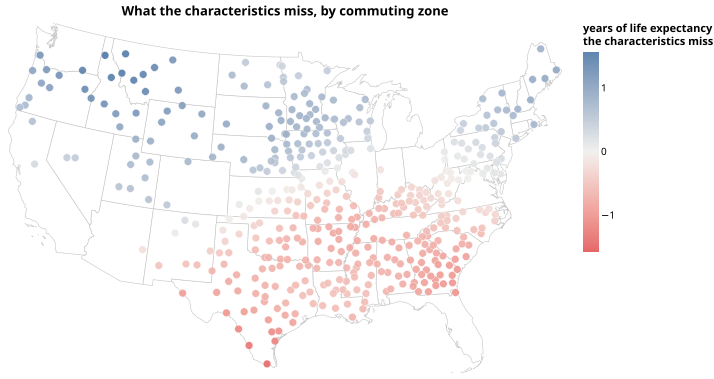

In [15]:
zones = alt.Chart(surface_frame).mark_circle(
    size=60, opacity=0.9, stroke="white", strokeWidth=0.4).encode(
    longitude="lon:Q",
    latitude="lat:Q",
    color=alt.Color(
        "years:Q",
        title=["years of life expectancy", "the characteristics miss"],
        scale=alt.Scale(domain=[-extent, 0.0, extent],
                        range=["#e15759", "#f0efec", "#4e79a7"],
                        interpolate="lab")),
    tooltip=["commuting zone:N", "state:N",
             alt.Tooltip("years:Q", format=".2f")],
)

(land + zones).project(type="albersUsa").properties(
    title="What the characteristics miss, by commuting zone",
    width=560, height=350)


Blue zones live longer than their characteristics predict, red zones shorter,
and a zone the characteristics get right is left almost uncoloured. The pattern
is regional, not a scatter of odd zones: a southern band runs low and the
northern plains, the Northwest and New England run high.


In [16]:
by_division = complete.select("census_div").with_columns(
    pl.Series("years", surface)
).group_by("census_div").agg(
    pl.col("years").mean().round(2).alias("mean years missed"),
    pl.len().alias("zones"),
).with_columns(
    pl.col("census_div").replace_strict(DIVISIONS).alias("census division")
).select(["census division", "mean years missed", "zones"]).sort(
    "mean years missed")
display(by_division)
# Compute the table or diagnostic interpreted in the following paragraph.

def name_list(names):
    names = list(names)
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " and " + names[-1]


surface_sd = f"{surface.std():.2f}"
surface_r = f"{np.corrcoef(surface, life_expectancy)[0, 1]:.2f}"
division_low = name_list(by_division["census division"][:2])
division_high = name_list(list(reversed(by_division["census division"][-3:])))
division_low_value = f"{abs(by_division['mean years missed'][0]):.2f}"
division_high_value = f"{by_division['mean years missed'][-1]:.2f}"
span = (by_division["mean years missed"][-1]
        - by_division["mean years missed"][0])
division_span = f"{span:.2f}"


census division,mean years missed,zones
str,f64,u32
"""South Central""",-0.63,146
"""South Atlantic""",-0.52,75
"""East North Central""",0.19,24
"""West North Central""",0.29,103
"""Middle Atlantic""",0.39,25
"""Mountain""",0.7,41
"""New England""",0.83,8
"""Pacific""",1.02,15


Averaged by census division, the {eval}`division_low` zones sit
{eval}`division_low_value` years below what their characteristics predict and
the {eval}`division_high` zones up to {eval}`division_high_value` above — a
{eval}`division_span`-year spread between regions that the
{eval}`n_characteristics` characteristics do not account for.

The spatial term was selected in all 200 half-sample fits alongside the
measured characteristics. This residual regional pattern suggests that the
recorded covariates and their fitted effects do not fully describe geographic
variation. The surface cannot identify its source: omitted characteristics,
measurement error and misspecified covariate effects can all leave spatial
structure.


## Results by gender and income quartile

The same procedure was run on all four groups — men and women, bottom and top
income quarter — and twice for each: once as above, with every zone counting
equally, and once with zones weighted by population, which is how the paper's
correlations are computed. Weighting is not a technicality: unweighted, the
answer describes the average commuting zone; weighted, it describes the average
American, and large cities dominate.

The chart shows every candidate that survived in at least one of those eight
runs, with its rate in each.


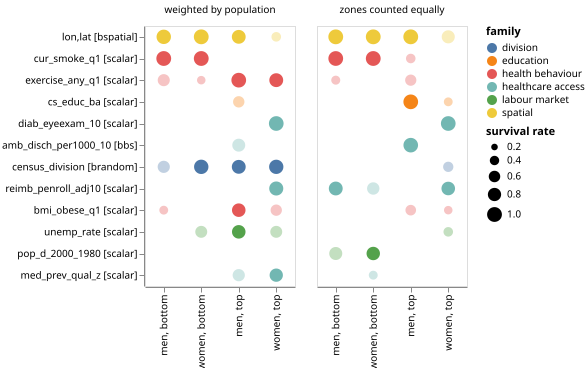

In [17]:
results = json.loads(pathlib.Path("cz_inequality.json").read_text())
labels = {"le_raceadj_q1_M": "men, bottom", "le_raceadj_q1_F": "women, bottom",
          "le_raceadj_q4_M": "men, top", "le_raceadj_q4_F": "women, top"}
weight_labels = {"unw": "zones counted equally",
                 "pop": "weighted by population"}
# Read the recorded experiment instead of rerunning its expensive fits.
grid_rows = []
for key, record in results["models"].items():
    ycol, weighting = key.rsplit("_", 1)
    for row in record["rows"]:
        grid_rows.append({
            "group": labels[ycol],
            "weighting": weight_labels[weighting],
            "candidate": row["learner"],
            "family": row["group"].replace("_", " "),
            "survival rate": row["freq"],
            "survived": row["freq"] >= record["cutoff"],
        })
grid = pl.DataFrame(grid_rows)
keep = grid.filter(pl.col("survived"))["candidate"].unique().to_list()
grid = grid.filter(pl.col("candidate").is_in(keep))

alt.Chart(grid).mark_circle().encode(
    x=alt.X("group:N", title=None,
            sort=["men, bottom", "women, bottom", "men, top", "women, top"]),
    y=alt.Y("candidate:N", title=None, sort=alt.EncodingSortField(
        "survival rate", op="max", order="descending")),
    size=alt.Size("survival rate:Q", title="survival rate",
                  scale=alt.Scale(domain=[0, 1], range=[0, 220])),
    color=alt.Color("family:N", title="family"),
    opacity=alt.condition(alt.datum.survived, alt.value(1.0), alt.value(0.35)),
    column=alt.Column("weighting:N", title=None),
    tooltip=["candidate:N", "group:N", "weighting:N",
             alt.Tooltip("survival rate:Q", format=".2f")],
).properties(width=150, height=260)


In [18]:
# Read the sentences below off the eight runs rather than restating them.
def rate_of(candidate, ycol, weighting):
    record = results["models"][f"{ycol}_{weighting}"]
    for row in record["rows"]:
        if row["learner"] == candidate:
            return row["freq"], row["freq"] >= record["cutoff"]
    return None, False

def survivors_of(ycol, weighting):
    record = results["models"][f"{ycol}_{weighting}"]
    return {row["learner"] for row in record["rows"]
            if row["freq"] >= record["cutoff"]}

def survivor_names(ycol, weighting):
    return ", ".join(name.split(" [")[0]
                     for name in sorted(survivors_of(ycol, weighting)))

stored_floor = min(row["freq"] for record in results["models"].values()
                   for row in record["rows"])

map_rates = {(y, w): rate_of("lon,lat [bspatial]", y, w)
             for y in labels for w in ("unw", "pop")}

n_map_survived_unw = sum(1 for (y, w), (_, ok) in map_rates.items()
                         if w == "unw" and ok)

map_q4f_unw = f"{map_rates[('le_raceadj_q4_F', 'unw')][0]:.2f}"

map_q4f_pop = f"{map_rates[('le_raceadj_q4_F', 'pop')][0]:.2f}"


In [19]:
smoke_bottom = [rate_of("cur_smoke_q1 [scalar]", y, w)[0]
                for y in ("le_raceadj_q1_M", "le_raceadj_q1_F")
                for w in ("unw", "pop")]
# Compute the table or diagnostic interpreted in the following paragraph.
smoke_bottom_low = f"{min(smoke_bottom):.2f}"

smoke_bottom_high = f"{max(smoke_bottom):.2f}"

geography = {"lon,lat [bspatial]", "census_division [brandom]"}

bottom_always = set.intersection(*(
    survivors_of(y, w) for y in ("le_raceadj_q1_M", "le_raceadj_q1_F")
    for w in ("unw", "pop"))) - geography

bottom_always_names = name_list(sorted(n.split(" [")[0]
                                       for n in bottom_always))

reimb_q1m_unw = f"{rate_of('reimb_penroll_adj10 [scalar]', 'le_raceadj_q1_M', 'unw')[0]:.2f}"

eye_q4f_unw = f"{rate_of('diab_eyeexam_10 [scalar]', 'le_raceadj_q4_F', 'unw')[0]:.2f}"

q4m_unw_set = survivor_names("le_raceadj_q4_M", "unw")

q4m_pop_set = survivor_names("le_raceadj_q4_M", "pop")

print("men, top quarter — zones counted equally:", q4m_unw_set)

print("men, top quarter — weighted by population:", q4m_pop_set)


men, top quarter — zones counted equally: amb_disch_per1000_10, cs_educ_ba, lon,lat
men, top quarter — weighted by population: bmi_obese_q1, census_division, exercise_any_q1, lon,lat, unemp_rate


A solid circle is a run where the candidate survived; a faded one is a rate
below the line; no circle means it was picked in under
{eval}`f"{stored_floor:.0%}"` of that run's fits, the floor the study scripts
stored.

**Geography survives almost everywhere.** With zones counted equally, the map
survives for {eval}`n_map_survived_unw` of the four groups. The
exception is women in the top quarter, where it reaches {eval}`map_q4f_unw`
unweighted and {eval}`map_q4f_pop` weighted — the one group whose life
expectancy the measured characteristics largely account for.

**Smoking is a bottom-quarter finding.** It survives in both bottom-quarter
groups under both weightings, at {eval}`smoke_bottom_low` to
{eval}`smoke_bottom_high`, and it is the only characteristic that survives all
four of those runs ({eval}`bottom_always_names`). In the top quarter it
survives nowhere. This is the half of the paper's summary that holds up.

**Healthcare is where the summary breaks.** With zones counted equally,
Medicare spending per enrollee survives for bottom-quarter men at
{eval}`reimb_q1m_unw` — a healthcare measure going with life expectancy in
exactly the group the paper's summary places it outside of. Weighted by
population it survives in neither bottom-quarter group. In the top quarter
healthcare measures survive under both weightings for women, diabetic eye-exam
rates at {eval}`eye_q4f_unw`.

**For top-quarter men the weighting decides the answer.** Counting zones
equally, the survivors are {eval}`q4m_unw_set`; weighting by population, they
are {eval}`q4m_pop_set`. Neither weighting is wrong. They answer different
questions, and a result quoted without saying which was used is not
interpretable.


## Conclusions

**Residual geographic variation.** The spatial term survived in every one of
the 200 half-sample fits and carries a {eval}`division_span`-year spread
between regions. With the {eval}`n_characteristics` measured characteristics
included, its standard deviation is about {eval}`surface_sd` years, compared
with {eval}`le_sd` for life expectancy itself. This quantifies the fitted
regional variation without identifying its cause.

**Smoking survives the harder test, for the poorest quarter.** It is the only
measured characteristic to survive in all four bottom-quarter runs. The
behavioural half of the published summary holds.

**Healthcare measures.** With zones counted equally, Medicare spending per
enrollee survives for bottom-quarter men. The weighting choice determines
whose average is described and should be reported with the result.

**Conditional selection differs from marginal correlation.** Here
{eval}`n_missed` characteristics correlate at least 0.3 with life expectancy
and do not survive, including the largest correlation in the set, while smoking
correlates {eval}`smoke_r` and survives in {eval}`smoke_rate` of fits. The
spatial term absorbs regional pattern shared by the area characteristics,
changing which terms provide additional predictive information.


## Limitations

A zone where more people smoke has lower life expectancy. That does not measure
what quitting would do for one person: the smoking rate and the life expectancy
are both zone averages, and many different person-level patterns inside a zone
produce the same pair of averages. Reading an area-level result as a
person-level effect is the ecological fallacy
{cite:p}`robinson1950ecological`, and it applies to every number here.

Selection records conditional predictive contributions rather than causal
effects. In particular, the spatial surface cannot distinguish an unmeasured
cause from measurement error or an inadequate form for a measured covariate.

The characteristics are measured at mixed dates — 2000 Census, 2010 ACS, pooled
BRFSS surveys — against life expectancy pooled over 2001-2014, so a
characteristic can stand in for a later change that nobody measured.


In [20]:
retained = raw.with_columns(
    pl.col("cz").is_in(complete["cz"].to_list()).alias("kept")
)
population = retained.group_by("kept").agg(
    pl.col("pop2000").median().alias("median pop2000"),
    pl.len().alias("zones"),
).sort("kept")
display(population)
# Compute the table or diagnostic interpreted in the following paragraph.
coverage = retained.group_by("census_div").agg(
    pl.len().alias("zones in file"),
    pl.col("kept").sum().alias("zones kept"),
).with_columns(
    (pl.col("zones kept") / pl.col("zones in file")).round(2).alias("share kept"),
    pl.col("census_div").replace_strict(DIVISIONS).alias("census division"),
).select(["census division", "zones in file", "zones kept",
          "share kept"]).sort("share kept")
display(coverage)

pop_dropped = f"{population['median pop2000'][0]:,.0f}"
pop_kept = f"{population['median pop2000'][1]:,.0f}"
worst_division = coverage["census division"][0]
worst_share = f"{coverage['share kept'][0]:.0%}"
best_division = coverage["census division"][-1]
best_share = f"{coverage['share kept'][-1]:.0%}"
top_division = by_division["census division"][-1]
top_row = coverage.filter(pl.col("census division") == top_division)
top_kept, top_total = top_row["zones kept"][0], top_row["zones in file"][0]


kept,median pop2000,zones
bool,f64,u32
false,243833.5,158
true,137456.0,437


census division,zones in file,zones kept,share kept
str,u32,u32,f64
"""East North Central""",85,24,0.28
"""Pacific""",44,15,0.34
"""New England""",14,8,0.57
"""South Atlantic""",105,75,0.71
"""Mountain""",55,41,0.75
"""South Central""",161,146,0.91
"""Middle Atlantic""",27,25,0.93
"""West North Central""",104,103,0.99


Dropping every zone with a missing value costs {eval}`n_dropped` of the
{eval}`n_zones_file` zones, {eval}`n_missing_dropout` of them for the missing
dropout rate alone. The dropped zones are the larger ones — median population
{eval}`pop_dropped` against {eval}`pop_kept` — and they are not dropped evenly
across the country, which matters most for the map, since the map is fitted on
whatever is left. {eval}`best_share` of the {eval}`best_division` zones survive
the filter and {eval}`worst_share` of the {eval}`worst_division` ones; the
{eval}`top_division` average above rests on {eval}`top_kept` of that division's
{eval}`top_total` zones.

The one-false-survivor bound holds under an assumption about the shape of the
selection probabilities that the data cannot check. The set of survivors was
recomputed under a second random seed and did not change.

The fitted map is shrunk toward zero, by an amount that depends on where
boosting was stopped. It shows a shape, not an unbiased estimate of how many
years a zone gains from its location.


```{bibliography}
:filter: docname in docnames
```